# What are Deepfakes?

- Face replacement in a video or a still image
- AI powered, using convolutional neural networks
- Runs on consumer hardware
- Works on ordinary video. No special cameras
- Data driven. No expert VFX skills required


# How did we get here?

From editing a photo by hand, to a model that alters a face on its own.


# Neural networks

- Built to follow the layout of the brain: many small units, linked together
- Learn pattern recognition and classification from examples
- A loss function measures how wrong the current answer is
- Training changes the network so that loss goes down


# The faceswap stack

A platform for neural networks and image processing.

- Face detection
- Face alignment
- Face recognition
- Face segmentation


# 1. Face detection

Given an image, find the box around each human face.

Three networks trade speed against accuracy:

- ResNet
- MTCNN
- S3FD


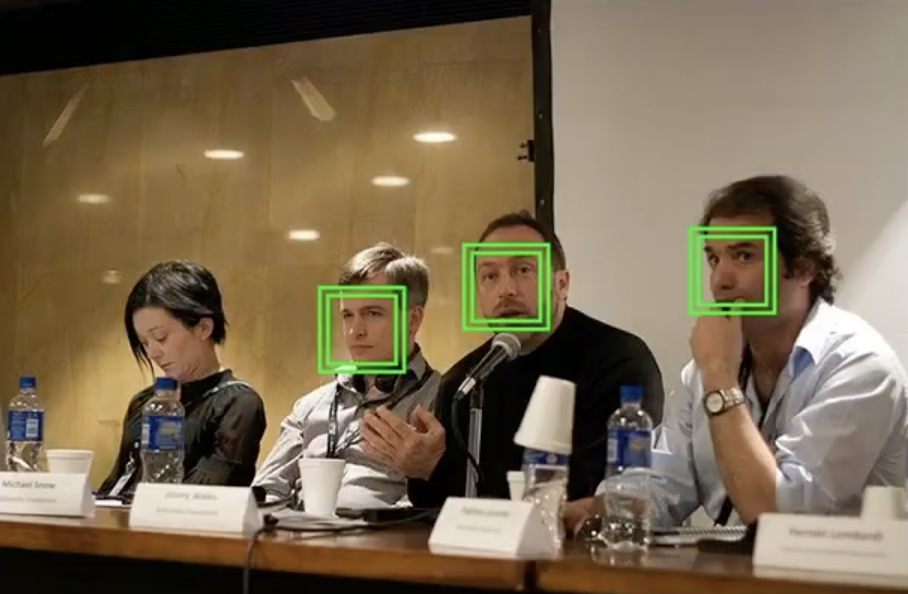

In [ ]:
from IPython.display import Image, display
display(Image("notebook_images/1.face_detection.png", width=720))


# 2. Face alignment

Identify the orientation and scale of each detected face with facial landmarks.

Two networks locate the landmarks:

- ResNet
- FAN

A point-registration step then scales the face to an upright, consistent pose.


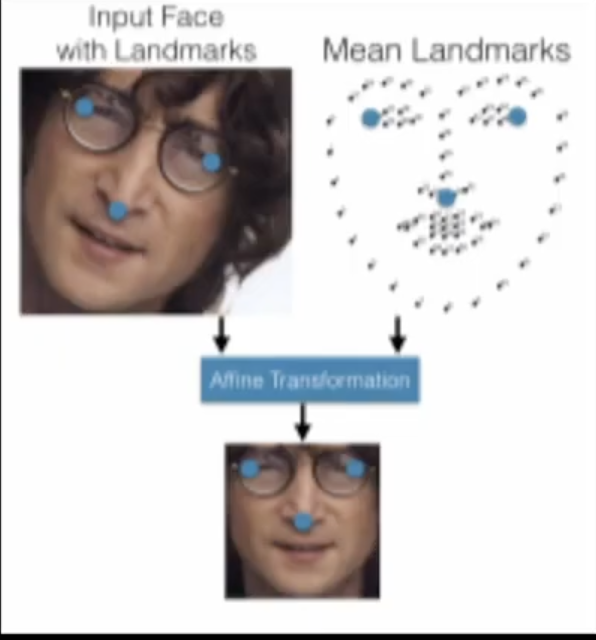

In [30]:
from IPython.display import Image, display
display(Image("notebook_images/2.face_alignment.png", width=420))


# 3. Face recognition

Encode each cropped face as numbers, and tell different people apart.

Three recognition networks:

- VGGFace v1
- VGGFace v2
- FaceNet

In a scene with several people, identities that are not wanted are discarded.


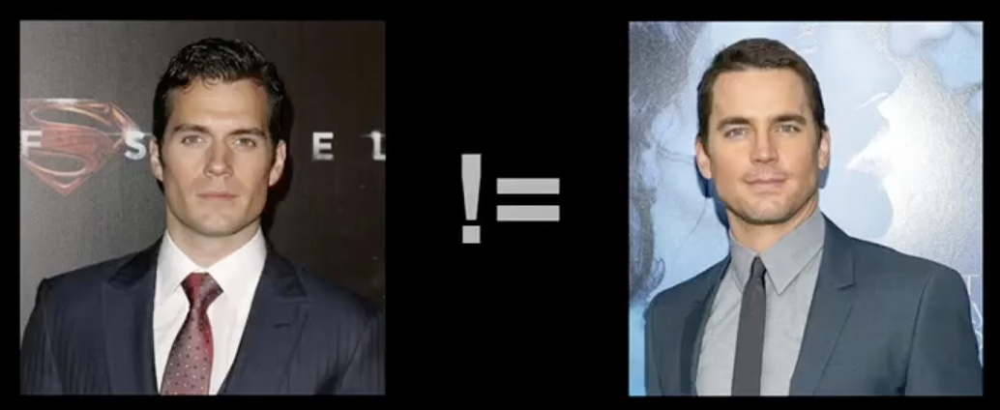

In [ ]:
from IPython.display import Image, display
display(Image("notebook_images/3.face_recoginition.png", width=720))


# 4. Face segmentation

Find the pixel mask of the face inside the crop.

Three segmentation networks:

- VGG-FCN v1
- VGG-FCN v2
- U-Net


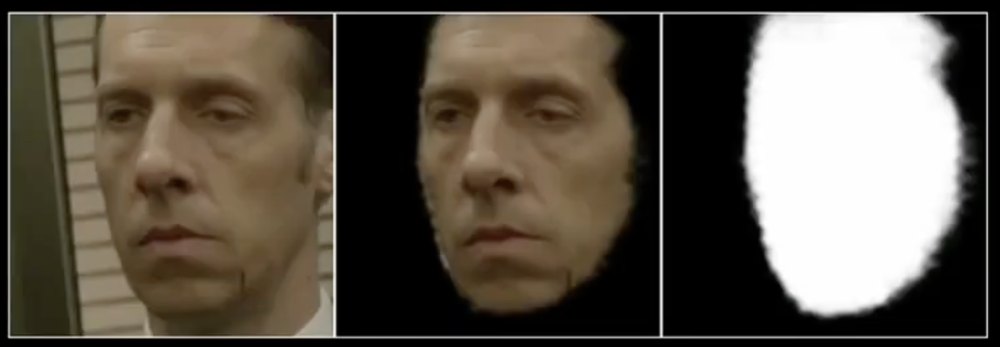

In [ ]:
from IPython.display import Image, display
display(Image("notebook_images/4.face_segmentation.png", width=720))


# The faceswap stack, continued

Platform for neural networks and image processing.

- Autoencoder training
- Image compositing
- Video splitting and splicing


# Image reconstruction with autoencoders

This is the neural-network core of the swap.

1. Reduce the image to a highly compressed representation.
2. That representation is the latent space.
3. Reconstruct the image from that lossy code.


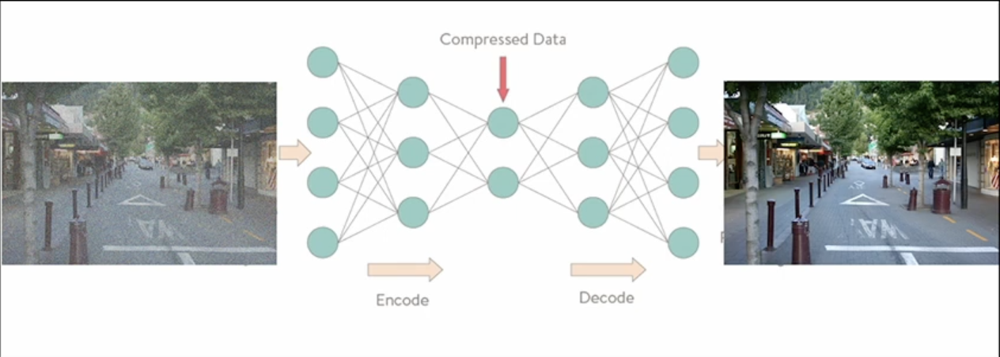

In [ ]:
from IPython.display import Image, display
display(Image("notebook_images/5.image_reconstruction_w_auto_encoder.png", width=720))


# Image reconstruction with autoencoders

- A single encoder network distills both subjects into a common representation.
- A unique decoder network for each subject recreates the original image.
- Ten network architectures use this idea, mixing speed and detail.


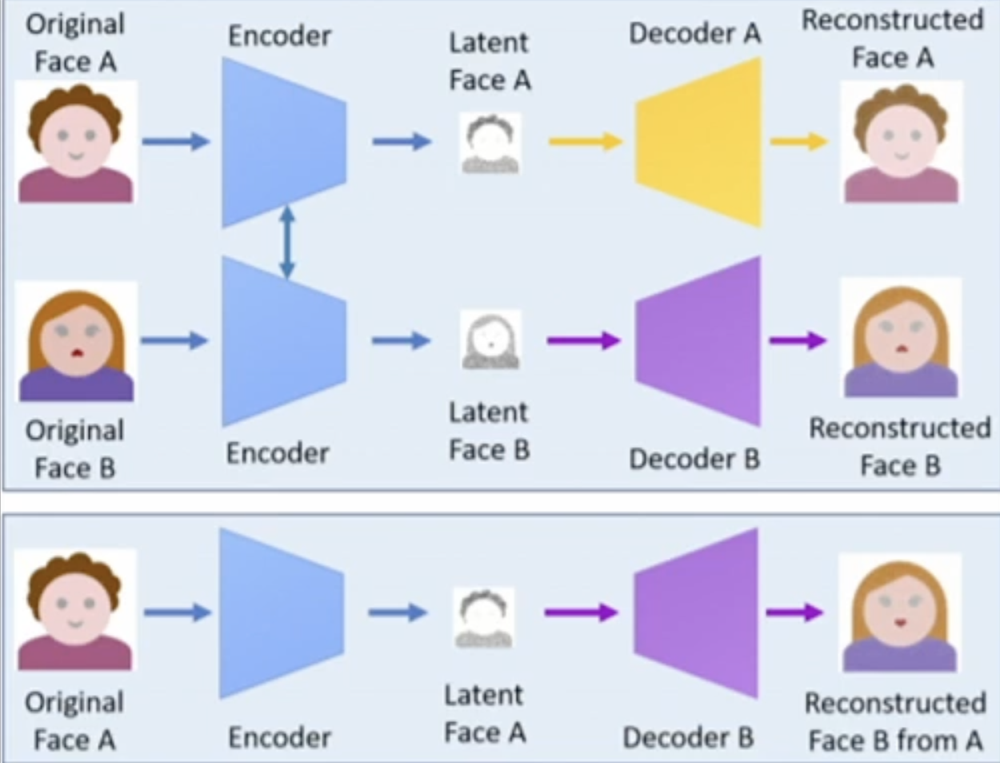

In [ ]:
from IPython.display import Image, display
display(Image("notebook_images/5.1.image_reconstruction_w_auto_encoder.png", width=720))


# Final steps: compositing and splicing

- Blend the new face in seamlessly.
- Invert the alignment, putting the face back in the frame.
- Splice each frame back into the video.


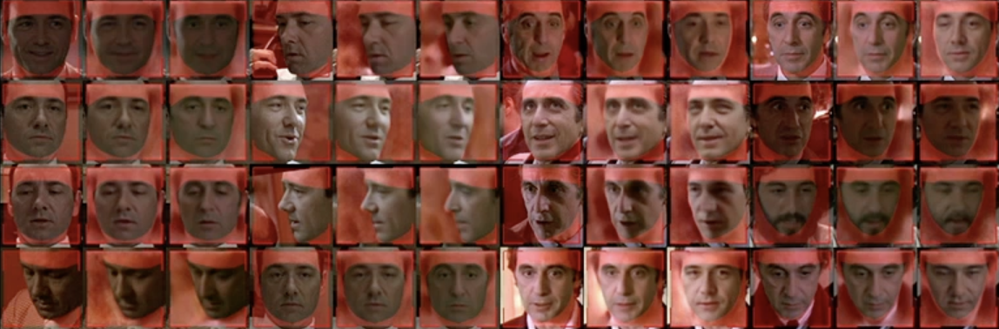

In [ ]:
from IPython.display import Image, display
display(Image("notebook_images/6.final_steps_composting_&_splicing.png", width=720))


# Faceswap process

**Gather data.** Find videos or images of the people whose faces you want to swap.

**Extract.** Pull every face out of that data, sort them, and drop the wrong faces.

**Train.** The model learns the swap.

**Convert.** Run the trained model on video or images and swap the faces.


# Face swap, one step at a time

Keep person 1. Copy person 2 onto that photo.

Photos live in `input/`. Boxes and the final swap are written to `output/`.

1. Import the libraries.
2. Load the face detector.
3. Load the swapper from `model/`, downloading it if the file is not there yet.
4. Read `input/person1.jpg`, then `input/person2.jpg`.
5. Mark each face and save the box to `output/`.
6. Straighten person 1 to 128×128, then person 2 to 112×112.
7. Turn person 2 into 512 numbers, then into the swapper's latent.
8. Paint a new face.
9. Warp it back, build a mask, and blend.
10. Run the same path with the people reversed. Save `output/swap.png`.


### 1. Imports

Nothing runs yet. Later cells use these names.


In [ ]:
# Installs InsightFace (detector, alignment, swapper) and ONNX Runtime 
%pip install -q insightface onnxruntime

12432.53s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /usr/local/opt/python@3.10/bin/python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# cv2 reads photos, numpy holds the numbers, pyplot draws the step under this cell.
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

# InsightFace finds the face, loads the swapper, and straightens a face onto a square.
from insightface.app import FaceAnalysis # detector + identity model
from insightface.model_zoo import get_model
from insightface.utils import face_align

# The library prints a lot while it loads. We hide that so the cell shows only our note.
import contextlib
import io

# input/ is the two people. output/ is the boxes and the swap. model/ is the model file.
for folder in ("input", "output", "model"):
    Path(folder).mkdir(exist_ok=True)

print("libraries imported")


libraries imported


### 2. A helper to draw each step

`show` puts the pictures for that step under the cell.


In [ ]:
# From here on, every step calls show() and you see only that step's picture.
def show(images, titles, save=None):
    def fit(image, height=320):
        h, w = image.shape[:2]
        return cv2.resize(image, (max(1, int(w * height / h)), height))

    panels = [fit(image) for image in images]
    fig, axes = plt.subplots(1, len(panels), figsize=(3.0 * len(panels), 3.5), gridspec_kw={"width_ratios": [p.shape[1] for p in panels]})
    if len(panels) == 1:
        axes = [axes]
    for ax, image, title in zip(axes, panels, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=120, bbox_inches="tight")
    plt.show()


### 3. Load the face detector

`buffalo_l` finds a face and reads who it is. It does not change the photo.


In [ ]:
# First model: the detector. It can find a face, but it does not change the photo.
# No picture is read in this cell. We only wake the model up.

# buffalo_l is a bundle: a face detector and a recognition network
with contextlib.redirect_stdout(io.StringIO()):
    app = FaceAnalysis(name="buffalo_l", providers=["CPUExecutionProvider"])
    app.prepare(ctx_id=-1, det_size=(640, 640))

print("detector ready:", ", ".join(app.models))


detector ready: landmark_3d_68, landmark_2d_106, detection, genderage, recognition


### 4. Load the swapper

The model file is `model/inswapper_128.onnx`. If that file is missing, this cell downloads the public InsightFace swap model into `model/` and then loads it.


In [ ]:
# Second model: the swapper. This is the model that will paint one face onto the other.
# If model/inswapper_128.onnx is already here, use it. If not, download it once, then load it.
MODEL = Path("model/inswapper_128.onnx")
URL = "https://github.com/deepinsight/insightface/releases/download/v0.7/inswapper_128.onnx"

if MODEL.is_file():
    print("using", MODEL)
else:
    print("not in model/, downloading...")
    part = MODEL.with_suffix(".part")
    urllib.request.urlretrieve(URL, part)
    part.replace(MODEL)
    print("saved", MODEL)

with contextlib.redirect_stdout(io.StringIO()):
    swapper = get_model(str(MODEL), providers=["CPUExecutionProvider"])

# Later it will want a 128x128 face, plus 512 numbers that say who the other person is.
print("image input:", swapper.input_size, " latent length:", swapper.emap.shape[0])


using model/inswapper_128.onnx
image input: (128, 128)  latent length: 512


### 5. Read person 1

This is the photo we keep: `input/person1.jpg`.


person 1 shape: (620, 494, 3)


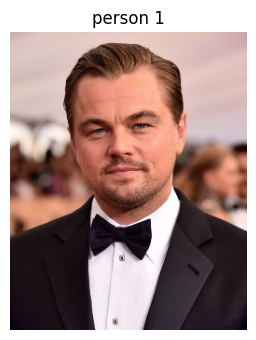

In [ ]:
# Person 1 is the photo we keep. Right now it is only pixels. No face has been found yet.
photo = cv2.imread("input/person1.jpg")
if photo is None:
    raise SystemExit("add a photo at input/person1.jpg")
print("person 1 shape:", photo.shape)
show([photo], ["person 1"])


### 6. Read person 2

This is the person we copy: `input/person2.jpg`.


person 2 shape: (500, 765, 3)


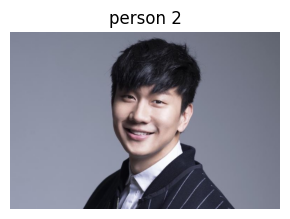

In [ ]:
# Person 2 is the face we will copy. Still just a photo, not a description of who they are.
identity_photo = cv2.imread("input/person2.jpg")
if identity_photo is None:
    raise SystemExit("add a photo at input/person2.jpg")
print("person 2 shape:", identity_photo.shape)
show([identity_photo], ["person 2"])


### 7. Find person 1's face

The detector returns a box and five points: eyes, nose, mouth corners. The picture is saved as `output/person1_box.jpg`.


person 1 box: [130.2, 87.1, 346.4, 358.2]


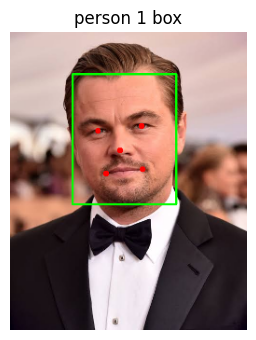

In [ ]:
# Runs detection, landmarks, and recognition on person 1.
# Find person 1. The green box is where the face is.
# The red dots are eyes, nose, and mouth corners. The next step uses those dots to straighten the face.
target = app.get(photo)[0]
print("person 1 box:", [round(float(v), 1) for v in target.bbox])

def mark(image, face):
    drawn = image.copy()
    x1, y1, x2, y2 = [int(v) for v in face.bbox]
    cv2.rectangle(drawn, (x1, y1), (x2, y2), (0, 255, 0), 3)
    for x, y in face.kps:
        cv2.circle(drawn, (int(x), int(y)), 6, (0, 0, 255), -1)
    return drawn

boxed = mark(photo, target)
cv2.imwrite("output/person1_box.jpg", boxed)
show([boxed], ["person 1 box"])


### 8. Find person 2's face

Same detector. The picture is saved as `output/person2_box.jpg`.


person 2 box: [292.6, 105.5, 484.9, 347.3]


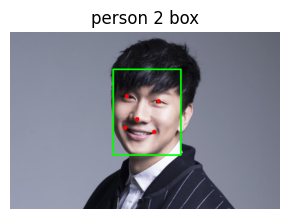

In [ ]:
# Same search on person 2. This face object also holds the identity we will copy later.
source = app.get(identity_photo)[0]
print("person 2 box:", [round(float(v), 1) for v in source.bbox])
boxed = mark(identity_photo, source)
cv2.imwrite("output/person2_box.jpg", boxed)
show([boxed], ["person 2 box"])


### 9. Straighten person 1

Warp person 1, using the five points, into the 128×128 square the swapper expects.


aligned person 1: (128, 128, 3)


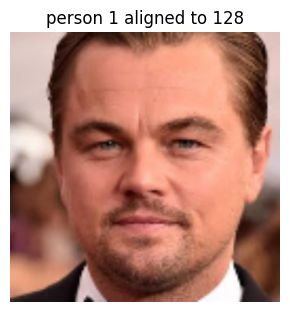

In [ ]:
# Straighten person 1 onto a 128x128 square, using the five dots.
# This square, not the whole photo, is what the swapper will look at. M remembers how to put the face back.
aligned, M = face_align.norm_crop2(photo, target.kps, swapper.input_size[0])
print("aligned person 1:", aligned.shape)
show([aligned], ["person 1 aligned to 128"])


### 10. Straighten person 2

The identity model uses a 112×112 square of the same kind.


aligned person 2: (112, 112, 3)


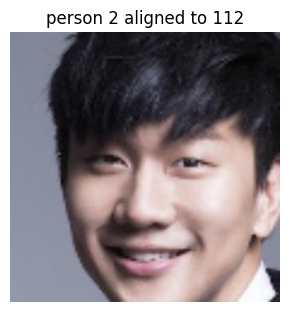

In [ ]:
# Straighten person 2 the same way, but to 112x112. That is the view the identity model used.
id_crop = face_align.norm_crop(identity_photo, source.kps, 112)
print("aligned person 2:", id_crop.shape)
show([id_crop], ["person 2 aligned to 112"])


### 11. Person 2 as 512 numbers

The face object already holds that identity. It is a vector, not a picture.


person 2 identity: (1, 512)


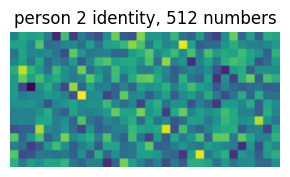

In [ ]:
# Person 2 stops being a picture here. 512 numbers now say who they are.
# The grid below is just those numbers, drawn so we can see them.
def as_map(values):
    grid = np.asarray(values, dtype=np.float32).reshape(16, 32)
    grid = cv2.normalize(grid, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return cv2.applyColorMap(cv2.resize(grid, (256, 128), interpolation=cv2.INTER_NEAREST), cv2.COLORMAP_VIRIDIS)

embedding = source.normed_embedding.reshape(1, -1)
print("person 2 identity:", embedding.shape)
show([as_map(embedding)], ["person 2 identity, 512 numbers"])


### 12. The latent the swapper wants

Multiply that vector by a fixed matrix stored in the model, then scale it to length 1.


latent: (1, 512)  length: 1.0


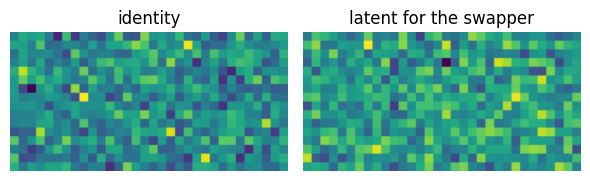

In [ ]:
# The swapper does not take those 512 numbers as-is.
# A fixed matrix inside the model turns them into its own latent, then we scale that vector to length 1.
latent = embedding @ swapper.emap
latent /= np.linalg.norm(latent)
print("latent:", latent.shape, " length:", round(float(np.linalg.norm(latent)), 4))
show([as_map(embedding), as_map(latent)], ["identity", "latent for the swapper"])


### 13. Paint the new face

Two inputs: aligned person 1, and person 2's latent. One output: a new 128×128 face in person 1's pose.


['target', 'source'] -> ['output']


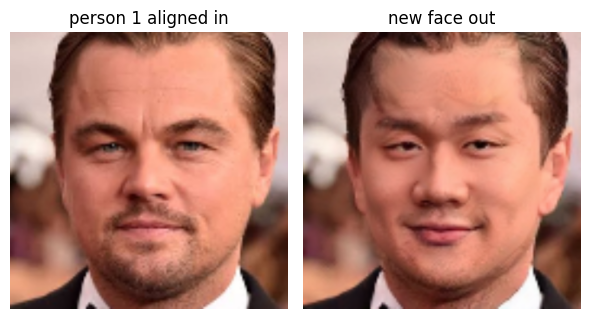

In [ ]:
# Two things go in: person 1's straightened face, and person 2's latent.
# One 128x128 face comes out, still in person 1's pose. We do not paste it onto the photo yet.
new_face, M = swapper.get(photo, target, source, paste_back=False)
print(swapper.input_names, "->", swapper.output_names)
show([aligned, new_face], ["person 1 aligned in", "new face out"])


### 14. Warp the new face back

Undo the alignment so the 128×128 face sits where A's face was.


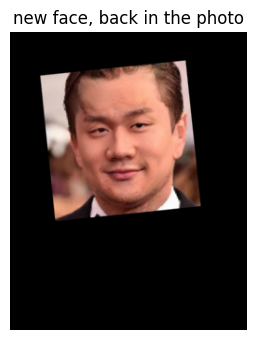

In [ ]:
# Undo the straightening, so the new face sits back where person 1's face was.
# Outside that face the frame is still black. The mask in the next step hides that black.
frame = (photo.shape[1], photo.shape[0])
placed = cv2.warpAffine(new_face, cv2.invertAffineTransform(M), frame)
show([placed], ["new face, back in the photo"])


### 15. Build the blend mask

A soft white region covers the face. Black means "keep the original photo".


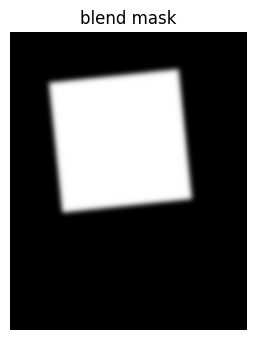

In [ ]:
# A white patch covers the face. Black means "keep the original photo".
# The edges are shrunk and blurred so the paste does not look cut out.
def face_mask(crop, transform, size):
    inv = cv2.invertAffineTransform(transform)
    white = np.full(crop.shape[:2], 255, np.float32)
    white = cv2.warpAffine(white, inv, size, borderValue=0)
    white[white > 20] = 255
    ys, xs = np.where(white == 255)
    side = int(np.sqrt((ys.max() - ys.min()) * (xs.max() - xs.min())))
    k = max(side // 10, 10)
    white = cv2.erode(white, np.ones((k, k), np.uint8))
    k = max(side // 20, 5)
    white = cv2.GaussianBlur(white, (2 * k + 1, 2 * k + 1), 0)
    return white / 255

mask = face_mask(aligned, M, frame)
mask_bgr = cv2.cvtColor((mask * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
show([mask_bgr], ["blend mask"])


### 16. Blend

White mask pixels take the new face. Black pixels keep person 1. The result is saved as `output/person1_with_person2.jpg`.


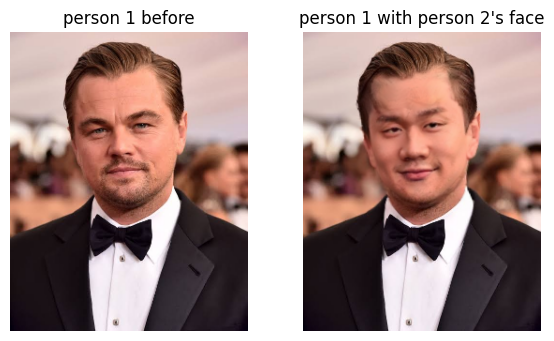

In [ ]:
# Where the mask is white, take the new face. Where it is black, keep person 1.
# That mix is the swap: person 1's photo, person 2's face.
mix = mask[:, :, None]
pasted = mix * placed.astype(np.float32) + (1.0 - mix) * photo.astype(np.float32)
pasted = np.clip(pasted, 0, 255).astype(np.uint8)
cv2.imwrite("output/person1_with_person2.jpg", pasted)
show([photo, pasted], ["person 1 before", "person 1 with person 2's face"])


### 17. The other direction

Same steps, roles reversed: keep person 2's photo, copy person 1's identity. The row is saved as `output/swap.png`.


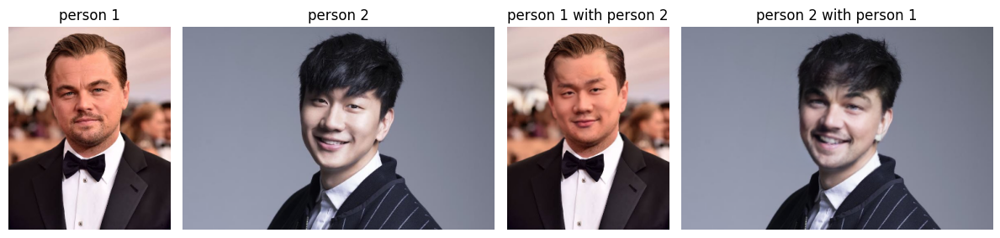

In [ ]:
# Same story, people reversed: keep person 2's photo, copy person 1's face.
# get() runs straighten, latent, paint, warp, and blend for that direction.
b_as_a = swapper.get(identity_photo, source, target)
cv2.imwrite("output/person2_with_person1.jpg", b_as_a)
show(
    [photo, identity_photo, pasted, b_as_a],
    ["person 1", "person 2", "person 1 with person 2", "person 2 with person 1"],
    save="output/swap.png",
)


# The next models

**CNN**<br>
↓<br>
**GAN** — adds a discriminator network<br>
↓<br>
**Diffusion**<br>
↓<br>
**DiT** — diffusion transformer<br>
↓<br>
**Flow matching**


# Assignment

Replace the face in this video with person 1 (`input/person1.jpg`).

`frames` is the video, one picture at a time. Fill in `swap_on_video`.

- `frames` — pictures from the clip
- `face_path` — `input/person1.jpg`, the face to copy
- `out_path` — `output/person1_on_video.mp4`
- `fps` — 25, the speed of this clip

Inside the function:

1. Read `face_path` once. `app.get(...)[0]` is person 1's face. Reuse that same face on every frame.
2. A `cv2.VideoWriter` is the object that builds the new `.mp4`. Open it on `out_path`. Give it `fps`, and the width and height of `frames[0]`. Width is `shape[1]`, height is `shape[0]`.
3. For each frame, `app.get(frame)` finds the face in that picture. `swapper.get(frame, face_in_frame, person_1_face)` returns the frame with person 1's face. `writer.write(...)` appends that picture to the video.
4. `writer.release()` closes the file. Until this runs, the mp4 is unfinished and will not play. `clip.release()` is the same idea for a video you opened to read.


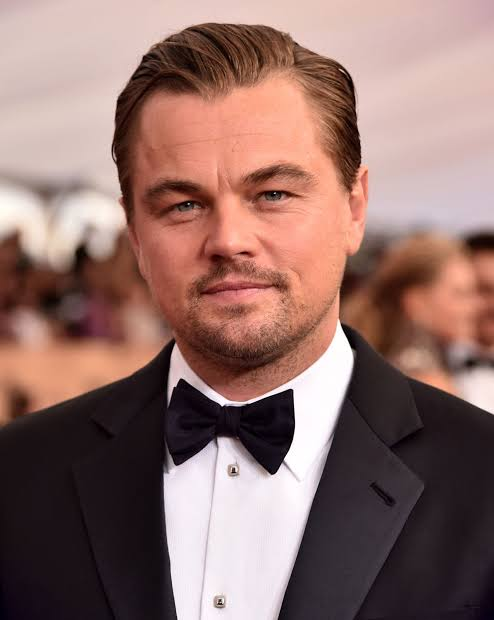

In [ ]:
from IPython.display import Image, Video, display
display(Image("input/person1.jpg", width=240))
display(Video("assignment/8048324-hd_1920_1080_25fps.mp4", embed=True, width=720))


In [ ]:
# Open the clip and take the frames out. The swap on each frame is left open.
clip = cv2.VideoCapture("assignment/8048324-hd_1920_1080_25fps.mp4")
frames = []
while True:
    ok, frame = clip.read()
    if not ok:
        break
    frames.append(frame)
clip.release()
print(len(frames), "frames", frames[0].shape)
show([frames[0]], ["first frame"])


In [ ]:
def swap_on_video(frames, face_path, out_path, fps=25):
    # frames: pictures from the video
    # face_path: person 1
    # out_path: new video to save
    # fps: frames per second
    pass


# swap_on_video(frames, "input/person1.jpg", "output/person1_on_video.mp4", fps=25)
